# Tensors with quantum numbers
We use the transverse field Ising model of `ImaginaryTimeEvolution.ipynb` to introduce tensors with a $\mathbb{Z}_2$ symmetry: the MPO of the Hamiltonian, a two-site operator and an MPS with a parity index. Every index of a symmetric tensor carries a charge, only the charge-conserving elements are stored, and the symmetry sector of a state can be fixed.

Contents:
1. MPO with Z2 quantum numbers, and the block structure of the Hamiltonian
2. A two-site operator with quantum numbers
3. Symmetric MPS

## Install
Import Cytnx, see https://cytnx-dev.github.io/Cytnx/
and
https://github.com/Cytnx-dev/Cytnx/issues/1189

```shell
python -m pip install -U --pre --extra-index-url https://pypi.anaconda.org/cytnx-nightly-wheels/simple cytnx-cuda
```
or
```shell
pixi add --pypi cytnx-cuda --index https://pypi.anaconda.org/cytnx-nightly-wheels/simple
```

In [1]:
# The following 2 lines are only needed if you installed Cytnx from source
# import sys
# sys.path.insert(0,'/home/manuel/Cytnx_lib') # change to your installation path

# The tensors in this notebook are small, so multithreading only adds overhead.
# The number of threads must be set before cytnx is imported.
import os
os.environ["OMP_NUM_THREADS"] = "1"

import cytnx
import cmath
import math
import time
import matplotlib.pyplot as plt
print(cytnx.__version__)

1.1.1


## MPS and MPO tensors, environments
The conventions and functions of `ImaginaryTimeEvolution.ipynb`: `mps_tensor` and `mpo_tensor` wrap a `cytnx.Tensor` into a `UniTensor` with site-dependent labels and bond directions, and `exp_val` contracts $\langle\text{bra}|O|\text{ket}\rangle$ with environments. The only change is in `init_env`: the boundary environment is the identity on the boundary bond, which matters once that bond has dimension 2 (section 3).

In [2]:
J = 1
beta = -0.7
D = 16

In [3]:
def mps_tensor(data, k):
    # MPS tensor of site k from a Tensor of shape (D_left, 2, D_right)
    Dl, d, Dr = data.shape()
    A = cytnx.UniTensor([cytnx.Bond(Dl, cytnx.BD_KET), cytnx.Bond(d, cytnx.BD_KET), cytnx.Bond(Dr, cytnx.BD_BRA)],
                        labels=[f"b{k}", f"s_{k}", f"b{k+1}"], rowrank=2, dtype=data.dtype(), name=f"A{k}")
    A.put_block(data.contiguous())
    return A

def mpo_tensor(data, k):
    # MPO tensor of site k from a Tensor of shape (D_left, D_right, 2, 2) with indices (v_k, v_k+1, s'_k, s_k)
    Dl, Dr, d, _ = data.shape()
    W = cytnx.UniTensor([cytnx.Bond(Dl, cytnx.BD_KET), cytnx.Bond(Dr, cytnx.BD_BRA),
                         cytnx.Bond(d, cytnx.BD_KET), cytnx.Bond(d, cytnx.BD_BRA)],
                        labels=[f"v{k}", f"v{k+1}", f"s'_{k}", f"s_{k}"], rowrank=2, dtype=data.dtype(), name=f"W{k}")
    W.put_block(data.contiguous())
    return W

In [4]:
def bra_tensor(bra, k, with_op):
    old = [f"b{k}", f"b{k+1}"]
    new = [f"c{k}", f"c{k+1}"]
    if with_op:
        old.append(f"s_{k}")
        new.append(f"s'_{k}")
    return bra[k].Dagger().relabel(old, new)

def init_env(ket, op, bra):
    N = len(ket)
    env = [None] * (N + 1)
    for j, k in [(0, 0), (N, N - 1)]:  # boundary bond j at site k
        bonds = [ket[k].bond(f"b{j}").redirect()]
        labels = [f"b{j}"]
        if op is not None:
            bonds.append(op[k].bond(f"v{j}").redirect())
            labels.append(f"v{j}")
        bonds.append(bra[k].bond(f"b{j}"))  # Dagger flips the direction of the bra bond
        labels.append(f"c{j}")
        E = cytnx.UniTensor(bonds, labels=labels, rowrank=len(bonds))
        for i in range(bonds[0].dim()):   # identity on the boundary bond: dimension 1, or the parity index of a symmetric MPS
            E.at([i] + [0] * (len(bonds) - 2) + [i]).value = 1
        env[j] = E
    return env

def absorb(E, k, ket, op, bra):
    # contract the environment E with the tensors of site k
    E = cytnx.Contract(E, ket[k])
    if op is not None:
        E = cytnx.Contract(E, op[k])
    return cytnx.Contract(E, bra_tensor(bra, k, op is not None))

def move_left(env, k, ket, op, bra):
    env[k + 1] = absorb(env[k], k, ket, op, bra)

def move_right(env, k, ket, op, bra):
    env[k] = absorb(env[k + 1], k, ket, op, bra)

def close_env(env, k, ket, op, bra):
    return cytnx.Contract(absorb(env[k], k, ket, op, bra), env[k + 1]).item()

In [5]:
def exp_val(ket, op=None, bra=None):
    if bra is None:
        bra = ket
    N = len(ket)
    env = init_env(ket, op, bra)
    for k in range(N - 1):
        move_left(env, k, ket, op, bra)
    return close_env(env, N - 1, ket, op, bra)

def energy(psi, H):
    return (exp_val(psi, H) / exp_val(psi)).real

## 1. MPO with Z2 quantum numbers
The Hamiltonian
$$
H = J \sum_{k=0}^{N-2} \sigma^z_k \sigma^z_{k+1} + \beta \sum_{k=0}^{N-1} \sigma^x_k
$$
commutes with the parity $P = \prod_k \sigma^x_k$, which has the eigenvalues $\pm 1$: a $\mathbb{Z}_2$ symmetry. A tensor with $\mathbb{Z}_2$ quantum numbers assigns a charge 0 or 1 to every index state, and only the elements whose charges add up to zero (mod 2) can be nonzero. Cytnx stores only these blocks and skips the rest in contractions.

The charges must be diagonal in the physical basis. In the usual basis $|\uparrow\rangle, |\downarrow\rangle$ (charges 0, 1) this is the case for $\tilde{P} = \prod_k \sigma^z_k$, so we implement
$$
\tilde{H} = J \sum_{k} \sigma^x_k \sigma^x_{k+1} + \beta \sum_{k} \sigma^z_k = H_\text{d}^{\otimes N}\, H\, H_\text{d}^{\otimes N} ,
$$
the same Hamiltonian in the basis rotated by the Hadamard matrix $H_\text{d} = (\sigma^x + \sigma^z) / \sqrt{2}$ on every site. Here $\sigma^x$ flips a spin and carries the charge 1, $\sigma^z$ and $I$ carry the charge 0. The MPO tensor is built in two steps:
1. `z2_operators(k)`: the operators $(I, \sigma^x, \sigma^z)$ of site $k$ in one tensor $O[o_k, s'_k, s_k]$, with the charges $(0, 1, 0)$ of the operators on the index $o_k$.
2. `z2_mpo_tensor(J, beta, k)`: the tensor $W[v_k, v_{k+1}, o_k]$ with the charges $(0, 1, 0)$ on all three indices places the operators in the channels of the MPO, like the $B$ tensor of `ising_mpo`. The middle channel has the charge 1, because one $\sigma^x$ of a $\sigma^x \sigma^x$ term has acted and the second one is still missing.

Contracting $o_k$ gives the MPO tensor with the indices and bond directions of `mpo_tensor`. `z2_boundaries` selects the first row of the first tensor and the last column of the last one, with outer bonds of dimension 1 and charge 0.

In [6]:
Z2 = cytnx.Symmetry.Zn(2)

def z2_bond(qnums, bondtype):
    # bond with one state for each entry of qnums, the Z2 charges of the states
    return cytnx.Bond(bondtype, [[q] for q in qnums], [1] * len(qnums), [Z2])

def z2_operators(k):
    # the operators I, sigma_x, sigma_z of site k in one tensor with the indices o{k}, s'_{k}, s_{k};
    # o{k} carries the charges 0, 1, 0 of the operators
    O = cytnx.UniTensor([z2_bond([0, 1, 0], cytnx.BD_BRA), z2_bond([0, 1], cytnx.BD_KET), z2_bond([0, 1], cytnx.BD_BRA)],
                        labels=[f"o{k}", f"s'_{k}", f"s_{k}"], rowrank=1, name=f"O{k}")
    O.at([0, 0, 0]).value = 1    # I
    O.at([0, 1, 1]).value = 1
    O.at([1, 0, 1]).value = 1    # sigma_x
    O.at([1, 1, 0]).value = 1
    O.at([2, 0, 0]).value = 1    # sigma_z
    O.at([2, 1, 1]).value = -1
    return O

def z2_mpo_tensor(J, beta, k):
    # W[v{k}, v{k+1}, o{k}] places the operators in the channels of the MPO; contracted with the operators over o{k}
    W = cytnx.UniTensor([z2_bond([0, 1, 0], cytnx.BD_KET), z2_bond([0, 1, 0], cytnx.BD_BRA), z2_bond([0, 1, 0], cytnx.BD_KET)],
                        labels=[f"v{k}", f"v{k+1}", f"o{k}"], rowrank=1)
    W.at([0, 0, 0]).value = 1      # I
    W.at([0, 1, 1]).value = J      # J sigma_x
    W.at([0, 2, 2]).value = beta   # beta sigma_z
    W.at([1, 2, 1]).value = 1      # sigma_x
    W.at([2, 2, 0]).value = 1      # I
    W = cytnx.Contract(W, z2_operators(k))
    W.permute_([f"v{k}", f"v{k+1}", f"s'_{k}", f"s_{k}"], rowrank=2)
    W.set_name_(f"W{k}")
    return W

def z2_boundaries(N):
    # the left tensor selects the first row of W_0, the right tensor the last column of W_{N-1}
    L = cytnx.UniTensor([z2_bond([0], cytnx.BD_KET), z2_bond([0, 1, 0], cytnx.BD_BRA)], labels=["left", "v0"], rowrank=1)
    L.at([0, 0]).value = 1
    R = cytnx.UniTensor([z2_bond([0, 1, 0], cytnx.BD_KET), z2_bond([0], cytnx.BD_BRA)], labels=[f"v{N}", "right"], rowrank=1)
    R.at([2, 0]).value = 1
    return L, R

def z2_ising_mpo(N, J, beta):
    # MPO of J sum sigma_x sigma_x + beta sum sigma_z with Z2 symmetric tensors
    mpo = [z2_mpo_tensor(J, beta, k) for k in range(N)]
    L, R = z2_boundaries(N)
    mpo[0] = cytnx.Contract(L, mpo[0]).relabel("left", "v0")
    mpo[N - 1] = cytnx.Contract(mpo[N - 1], R).relabel("right", f"v{N}")
    for k in [0, N - 1]:
        mpo[k].permute_([f"v{k}", f"v{k+1}", f"s'_{k}", f"s_{k}"], rowrank=2)
        mpo[k].set_name_(f"W{k}")
    return mpo

**Test:** the symmetric MPO, contracted to a matrix and rotated back with $H_\text{d}^{\otimes N}$, must equal the dense matrix of $H$. `convert_from_` copies the blocks into a tensor without symmetry.

In [7]:
def hadamard():
    return (cytnx.physics.pauli("x").real() + cytnx.physics.pauli("z").real()) / math.sqrt(2)

def z2_dense_hamiltonian(N, J, beta):
    # matrix of the symmetric MPO, rotated with Hadamard matrices on all sites
    mpo = z2_ising_mpo(N, J, beta)
    H = mpo[0]
    for k in range(1, N):
        H = cytnx.Contract(H, mpo[k])
    dense = cytnx.UniTensor([cytnx.Bond(b.dim(), b.type()) for b in H.bonds()], labels=H.labels(), rowrank=H.rowrank())
    dense.convert_from_(H)
    row_labels = ["v0"] + [f"s'_{k}" for k in range(N)]
    col_labels = [f"v{N}"] + [f"s_{k}" for k in range(N)]
    H = dense.permute(row_labels + col_labels, rowrank=N + 1).get_block().contiguous().reshape(2 ** N, 2 ** N)
    Hd = hadamard()
    for k in range(1, N):
        Hd = cytnx.linalg.Kron(Hd, hadamard())
    return cytnx.linalg.Matmul(Hd, cytnx.linalg.Matmul(H, Hd))

def dense_hamiltonian_zz(N, J, beta):
    # J sum sigma_z sigma_z + beta sum sigma_x as a matrix: the B tensor of ising_mpo with x and z exchanged
    sx = cytnx.physics.pauli("x").real()
    sz = cytnx.physics.pauli("z").real()
    B_data = cytnx.zeros([3, 3, 2, 2])
    B_data[0, 0, :, :] = cytnx.eye(2)
    B_data[0, 1, :, :] = J * sz
    B_data[0, 2, :, :] = beta * sx
    B_data[1, 2, :, :] = sz
    B_data[2, 2, :, :] = cytnx.eye(2)
    H = mpo_tensor(B_data[0:1, :, :, :].clone(), 0)
    for k in range(1, N):
        H = cytnx.Contract(H, mpo_tensor((B_data[:, 2:3, :, :] if k == N - 1 else B_data).clone(), k))
    row_labels = ["v0"] + [f"s'_{k}" for k in range(N)]
    col_labels = [f"v{N}"] + [f"s_{k}" for k in range(N)]
    return H.permute(row_labels + col_labels, rowrank=N + 1).get_block().contiguous().reshape(2 ** N, 2 ** N)

for N_test in [2, 3, 6]:
    difference = (z2_dense_hamiltonian(N_test, J, beta) - dense_hamiltonian_zz(N_test, J, beta)).norm()
    print(f"N = {N_test}: |H(Z2 MPO) - H(dense)| = {difference:.1e}")

N = 2: |H(Z2 MPO) - H(dense)| = 1.0e-15
N = 3: |H(Z2 MPO) - H(dense)| = 2.9e-15
N = 6: |H(Z2 MPO) - H(dense)| = 2.0e-14


The block structure of a tensor in the bulk: of the $3 \cdot 3 \cdot 2 \cdot 2 = 36$ elements, only the 18 that conserve the charge exist as blocks (each $1 \times 1 \times 1 \times 1$, since every index state has its own charge), and 10 of them are nonzero.

In [8]:
W = z2_ising_mpo(4, J, beta)[1]
W.print_diagram()
print(W)

-----------------------
tensor Name : W1
tensor Rank : 4
contiguous  : True
valid blocks: 18
is diag     : False
on device   : cytnx device: CPU
       row           col 
          -----------    
          |         |    
   v1  -->| 3     2 |<--* s'_1
          |         |    
   v2 *<--| 3     2 |-->  s_1
          |         |    
          -----------    

-------- start of print ---------
Tensor name: W1
Tensor type: Block
braket_form : False
is_diag    : False
[OVERALL] contiguous : True
BLOCK [#0]
 |- []   : Qn index 
 |- Sym(): Qnum of correspond symmetry
                 -----------
                 |         |
   [0] Z2(0)  -->| 1     1 |<--* [0] Z2(0)
                 |         |
   [0] Z2(0) *<--| 1     1 |-->  [0] Z2(0)
                 |         |
                 -----------

Total elem: 1
type  : Double (Float64)
cytnx device: CPU
Shape : (1,1,1,1)
[[[[1.00000e+00 ]]]]

BLOCK [#1]
 |- []   : Qn index 
 |- Sym(): Qnum of correspond symmetry
                 -----------
 

### Block structure of the full Hamiltonian
The charge of a basis state $|s_0 s_1 \cdots s_{N-1}\rangle$ is the sum of the charges of its sites, the number of $\downarrow$ spins mod 2. $\tilde{H}$ has no matrix elements between the two charge sectors: in the usual order of the basis states the nonzero elements look scattered, after sorting the states by their charge the matrix is block diagonal with two blocks of size $2^{N-1}$. The rotated $H$ has the same two blocks in the eigenbasis of $P = \prod_k \sigma^x_k$.

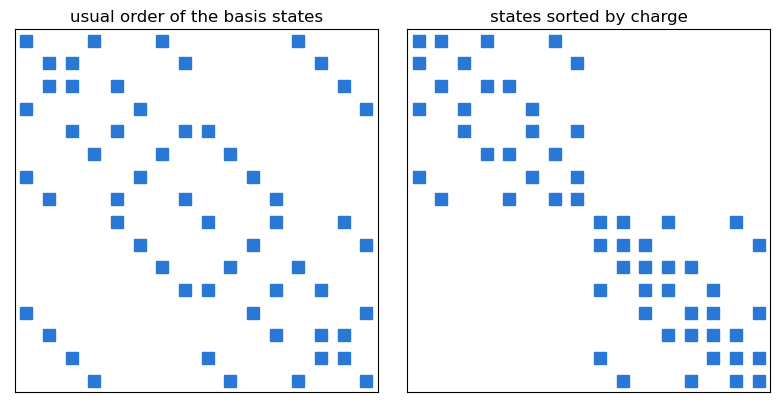

In [9]:
def charge_sorted(H_matrix, N):
    # rows and columns of H_matrix reordered: states with an even number of down spins first, then odd
    order = sorted(range(2 ** N), key=lambda s: bin(s).count("1") % 2)
    sorted_matrix = cytnx.zeros([2 ** N, 2 ** N])
    for i, r in enumerate(order):
        for j, c in enumerate(order):
            sorted_matrix[i, j] = H_matrix[r, c]
    return sorted_matrix

N_plot = 4
mpo = z2_ising_mpo(N_plot, J, beta)
H = mpo[0]
for k in range(1, N_plot):
    H = cytnx.Contract(H, mpo[k])
dense = cytnx.UniTensor([cytnx.Bond(b.dim(), b.type()) for b in H.bonds()], labels=H.labels(), rowrank=H.rowrank())
dense.convert_from_(H)
row_labels = ["v0"] + [f"s'_{k}" for k in range(N_plot)]
col_labels = [f"v{N_plot}"] + [f"s_{k}" for k in range(N_plot)]
H_tilde = dense.permute(row_labels + col_labels, rowrank=N_plot + 1).get_block().contiguous().reshape(2 ** N_plot, 2 ** N_plot)

fig, axes = plt.subplots(1, 2, figsize=(8, 4))
for ax, matrix, title in [(axes[0], H_tilde, "usual order of the basis states"),
                          (axes[1], charge_sorted(H_tilde, N_plot), "states sorted by charge")]:
    ax.spy(matrix.numpy(), markersize=8, color="#2a78d6")
    ax.set_title(title)
    ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout()
plt.show()

## 2. A two-site operator with quantum numbers
$\sigma^x$ changes the charge of a site, so as a symmetric tensor it needs a third index that carries away the charge 1. In the product $\sigma^x_0 \sigma^x_1$ the charge that leaves site 0 enters site 1: we give each $\sigma^x$ a dummy index of dimension 1 with the charge 1, outgoing on site 0 and incoming on site 1, and contract the two. The result is the four-leg tensor $T = \sigma^x_0 \sigma^x_1$, which conserves the total charge of the two sites.

In [10]:
def z2_sigma_x(k, dummy_direction):
    # sigma_x of site k with a dummy index "d" of charge 1
    O = cytnx.UniTensor([z2_bond([1], dummy_direction), z2_bond([0, 1], cytnx.BD_KET), z2_bond([0, 1], cytnx.BD_BRA)],
                        labels=["d", f"s'_{k}", f"s_{k}"], rowrank=2, name=f"sigma_x{k}")
    O.at([0, 0, 1]).value = 1
    O.at([0, 1, 0]).value = 1
    return O

T = cytnx.Contract(z2_sigma_x(0, cytnx.BD_BRA), z2_sigma_x(1, cytnx.BD_KET))
T.permute_(["s'_0", "s'_1", "s_0", "s_1"], rowrank=2)
T.set_name_("sigma_x0 sigma_x1")
T.print_diagram()
print(T)

-----------------------
tensor Name : sigma_x0 sigma_x1
tensor Rank : 4
contiguous  : False
valid blocks: 8
is diag     : False
on device   : cytnx device: CPU
         row           col 
            -----------    
            |         |    
   s'_0  -->| 2     2 |-->  s_0
            |         |    
   s'_1  -->| 2     2 |-->  s_1
            |         |    
            -----------    

-------- start of print ---------
Tensor name: sigma_x0 sigma_x1
Tensor type: Block
braket_form : True
is_diag    : False
[OVERALL] contiguous : False
BLOCK [#0]
 |- []   : Qn index 
 |- Sym(): Qnum of correspond symmetry
                 -----------
                 |         |
   [0] Z2(0)  -->| 1     1 |-->  [0] Z2(0)
                 |         |
   [0] Z2(0)  -->| 1     1 |-->  [0] Z2(0)
                 |         |
                 -----------

Total elem: 1
type  : Double (Float64)
cytnx device: CPU
Shape : (1,1,1,1)
[[[[0.00000e+00 ]]]]

BLOCK [#1]
 |- []   : Qn index 
 |- Sym(): Qnum of corre

The 8 blocks of $T$ are the elements between single-site charge sectors. `combineBonds` merges the two incoming legs into one index of the two-site Hilbert space, and the two outgoing ones likewise; `force=True` allows this for indices that carry charges. The combined index has the charge sectors 0 ($\uparrow\uparrow, \downarrow\downarrow$) and 1 ($\uparrow\downarrow, \downarrow\uparrow$) of dimension 2 each, so only 2 blocks of size $2 \times 2$ remain: the matrix of $\sigma^x_0 \sigma^x_1$ is block diagonal in the total charge.

In [11]:
T_matrix = T.clone()
T_matrix.combineBonds(["s'_0", "s'_1"], force=True)
T_matrix.combineBonds(["s_0", "s_1"], force=True)
T_matrix.print_diagram()
print(T_matrix)

-----------------------
tensor Name : sigma_x0 sigma_x1
tensor Rank : 2
contiguous  : True
valid blocks: 2
is diag     : False
on device   : cytnx device: CPU
         row           col 
            -----------    
            |         |    
   s'_0  -->| 4     4 |-->  s_0
            |         |    
            -----------    

-------- start of print ---------
Tensor name: sigma_x0 sigma_x1
Tensor type: Block
braket_form : True
is_diag    : False
[OVERALL] contiguous : True
BLOCK [#0]
 |- []   : Qn index 
 |- Sym(): Qnum of correspond symmetry
                 -----------
                 |         |
   [0] Z2(0)  -->| 2     2 |-->  [0] Z2(0)
                 |         |
                 -----------

Total elem: 4
type  : Double (Float64)
cytnx device: CPU
Shape : (2,2)
[[0.00000e+00 1.00000e+00 ]
 [1.00000e+00 0.00000e+00 ]]

BLOCK [#1]
 |- []   : Qn index 
 |- Sym(): Qnum of correspond symmetry
                 -----------
                 |         |
   [1] Z2(1)  -->| 2     2 |-

/tmp/ipykernel_15020/2866472892.py:2: DeprecationWarning: combineBonds() is deprecated, use combineBond_()/combineBond() instead.
  T_matrix.combineBonds(["s'_0", "s'_1"], force=True)
/tmp/ipykernel_15020/2866472892.py:3: DeprecationWarning: combineBonds() is deprecated, use combineBond_()/combineBond() instead.
  T_matrix.combineBonds(["s_0", "s_1"], force=True)


With `rowrank=2`, the SVD treats $T$ as the matrix from the incoming indices $(s_0, s_1)$ to the outgoing indices $(s'_0, s'_1)$ of the two-site Hilbert space. The combined index of two sites has the charge sectors 0 ($\uparrow\uparrow, \downarrow\downarrow$) and 1 ($\uparrow\downarrow, \downarrow\uparrow$), and the SVD is done in each sector separately: the singular values come in two blocks, and the new index between $U$ and $V^\dagger$ carries the charges. All singular values are 1, since $\sigma^x_0 \sigma^x_1$ is unitary.

In [12]:
S, U, Vt = cytnx.linalg.Svd(T)
print(S)
U.print_diagram()

-------- start of print ---------
Tensor name: 
Tensor type: Block
braket_form : True
is_diag    : True
[OVERALL] contiguous : True
 *is_diag: True
BLOCK [#0]
 |- []   : Qn index 
 |- Sym(): Qnum of correspond symmetry
                 -----------
                 |         |
   [0] Z2(0)  -->| 2     2 |-->  [0] Z2(0)
                 |         |
                 -----------

Total elem: 2
type  : Double (Float64)
cytnx device: CPU
Shape : (2)
[1.00000e+00 1.00000e+00 ]

 *is_diag: True
BLOCK [#1]
 |- []   : Qn index 
 |- Sym(): Qnum of correspond symmetry
                 -----------
                 |         |
   [1] Z2(1)  -->| 2     2 |-->  [1] Z2(1)
                 |         |
                 -----------

Total elem: 2
type  : Double (Float64)
cytnx device: CPU
Shape : (2)
[1.00000e+00 1.00000e+00 ]



-----------------------
tensor Name : 
tensor Rank : 3
contiguous  : True
valid blocks: 4
is diag     : False
on device   : cytnx device: CPU
         row           col 
        

## 3. Symmetric MPS
In a symmetric MPS every bond carries charges as well. The charge of a bond state is the total charge of the sites to its left, so the charges of a basis state flow through the chain and leave it at the boundary: the bond `b0` of the first tensor carries the charge of the whole state, the **parity index**. With a single charge 0 or 1 on `b0`, the MPS only contains states with an even or odd number of $\downarrow$ spins. With both charges, `b0` has dimension 2 and the MPS is a superposition of both sectors, like an MPS without symmetry. The bond `bN` on the right has charge 0.

`z2_random_mps` creates a random MPS of bond dimension $D$ with `parity` = 0, 1 or (0, 1); the states of the inner bonds alternate between the charges 0 and 1.

In [13]:
def z2_mps_tensor(left_qnums, right_qnums, k):
    # empty symmetric MPS tensor of site k with the charges of the bonds b{k}, b{k+1}
    return cytnx.UniTensor([z2_bond(left_qnums, cytnx.BD_KET), z2_bond([0, 1], cytnx.BD_KET), z2_bond(right_qnums, cytnx.BD_BRA)],
                           labels=[f"b{k}", f"s_{k}", f"b{k+1}"], rowrank=2, name=f"A{k}")

def z2_random_mps(N, D, parity, seed=0):
    # random MPS with bond dimension D; parity = 0, 1 or (0, 1) gives the charges of the parity index b0
    qnums = [list(parity) if isinstance(parity, (list, tuple)) else [parity]]
    qnums += [[j % 2 for j in range(min(D, 2 ** k, 2 ** (N - k)))] for k in range(1, N)] + [[0]]
    psi = []
    for k in range(N):
        A = z2_mps_tensor(qnums[k], qnums[k + 1], k)
        cytnx.random.uniform_(A, -1, 1, seed=seed + k)
        A = A / A.norm()
        A.set_name_(f"A{k}")
        psi.append(A)
    return psi

psi_odd = z2_random_mps(4, 4, parity=1)
psi_odd[0].print_diagram()
print(psi_odd[0])

-----------------------
tensor Name : A0
tensor Rank : 3
contiguous  : True
valid blocks: 2
is diag     : False
on device   : cytnx device: CPU
        row           col 
           -----------    
           |         |    
   b0   -->| 1     2 |-->  b1
           |         |    
   s_0  -->| 2       |        
           |         |    
           -----------    

-------- start of print ---------
Tensor name: A0
Tensor type: Block
braket_form : True
is_diag    : False
[OVERALL] contiguous : True
BLOCK [#0]
 |- []   : Qn index 
 |- Sym(): Qnum of correspond symmetry
                 -----------
                 |         |
   [0] Z2(1)  -->| 1     1 |-->  [1] Z2(1)
                 |         |
   [0] Z2(0)  -->| 1       |
                 |         |
                 -----------

Total elem: 1
type  : Double (Float64)
cytnx device: CPU
Shape : (1,1,1)
[[[1.83567e-01 ]]]

BLOCK [#1]
 |- []   : Qn index 
 |- Sym(): Qnum of correspond symmetry
                 -----------
               

**Test:** the state vector of the MPS must be an eigenstate of $\tilde{P} = \prod_k \sigma^z_k$ with the eigenvalue $(-1)^\text{parity}$ for a single parity, and a superposition with $|\langle \tilde{P} \rangle| < 1$ for both; `exp_val` with the symmetric MPO must give the same energy as the dense $\tilde{H}$. For the parity index $(0, 1)$, the boundary environment of `init_env` is the identity on `b0`, so `exp_val` sums the two sectors: $\langle\psi_0|\tilde{H}|\psi_0\rangle + \langle\psi_1|\tilde{H}|\psi_1\rangle$. This is the energy of $\psi_0 + \psi_1$, because $\tilde{H}$ has no matrix elements between the sectors.

In [14]:
def z2_mps_to_dense(psi):
    N = len(psi)
    T = psi[0]
    for k in range(1, N):
        T = cytnx.Contract(T, psi[k])
    dense = cytnx.UniTensor([cytnx.Bond(b.dim(), b.type()) for b in T.bonds()], labels=T.labels(), rowrank=T.rowrank())
    dense.convert_from_(T)
    dense = dense.permute(["b0"] + [f"s_{k}" for k in range(N)] + [f"b{N}"], rowrank=N + 2)
    return dense.get_block().contiguous().reshape(-1, 2 ** N)   # one row per state of the parity index

N_test = 4
Hd = hadamard()
for k in range(1, N_test):
    Hd = cytnx.linalg.Kron(Hd, hadamard())
H_tilde_test = cytnx.linalg.Matmul(Hd, cytnx.linalg.Matmul(z2_dense_hamiltonian(N_test, J, beta), Hd))
mpo = z2_ising_mpo(N_test, J, beta)
for parity in [0, 1, (0, 1)]:
    psi = z2_random_mps(N_test, 4, parity)
    vec = z2_mps_to_dense(psi)
    vec = cytnx.linalg.Matmul(cytnx.ones([1, vec.shape()[0]]), vec).reshape(-1)   # sum over the parity index
    parity_vec = cytnx.zeros(2 ** N_test)
    for s in range(2 ** N_test):
        parity_vec[s] = (-1) ** bin(s).count("1") * vec[s].item()
    norm = cytnx.linalg.Vectordot(vec, vec).item()
    E_dense = cytnx.linalg.Vectordot(vec, cytnx.linalg.Matmul(H_tilde_test, vec.reshape(-1, 1)).reshape(-1)).item() / norm
    print(f"parity {str(parity):6s}: <P~> = {cytnx.linalg.Vectordot(vec, parity_vec).item() / norm:+.3f}, "
          f"E(MPO) - E(dense) = {energy(psi, mpo) - E_dense:.1e}")

parity 0     : <P~> = +1.000, E(MPO) - E(dense) = 5.6e-16
parity 1     : <P~> = -1.000, E(MPO) - E(dense) = 1.0e-15
parity (0, 1): <P~> = -0.066, E(MPO) - E(dense) = 8.9e-16
